## Intelligent Legal Question-Answering System based on Iranian Laws

This project implements a Retrieval-Augmented Generation (RAG) agent that answers legal questions in Persian using a curated dataset of Iranian legal documents. The pipeline covers data preparation (PDF text extraction and OCR), vector database construction, agent design with LangGraph, temporal performance analysis, retrieval quality evaluation with RAGAS, and an interactive Chainlit UI.

## Import All Libraries

In [ ]:
import os
import io
import re
import fitz
import time
import gdown
import shutil
import lancedb
import warnings
import numpy as np
import pandas as pd
from PIL import Image
from ragas import evaluate
from functools import wraps
from datasets import Dataset
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from vllm import LLM, SamplingParams
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from IPython.display import Image, display
from lancedb.embeddings import get_registry
from langgraph.graph import StateGraph, END
from langchain_core.documents import Document
from lancedb.pydantic import LanceModel, Vector
from sentence_transformers import SentenceTransformer
from langchain_core.prompts import ChatPromptTemplate
from sklearn.metrics.pairwise import cosine_similarity
from langchain_huggingface import HuggingFaceEmbeddings
from ragas.metrics import faithfulness, answer_relevancy
from typing import List, TypedDict, Optional, Dict, Any, Literal
from langchain_text_splitters import RecursiveCharacterTextSplitter
from vllm.model_executor.models.deepseek_ocr import NGramPerReqLogitsProcessor
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser


warnings.filterwarnings('ignore')

## 1. Dataset Acquisition

Separates text-based PDFs from scanned ones, and extracts raw text from selectable PDFs using PyMuPDF.

In [ ]:
dataset_dir = "Iranian_Laws_data"
output_zip = f"{dataset_dir}.zip"
output_text_dir = f"{dataset_dir}_text"

try:
    if not os.path.exists(output_zip):
        raise FileNotFoundError(f"The file {output_zip} was not found in the current directory.")
    
    os.makedirs(output_text_dir, exist_ok=True)

    if not os.listdir(output_text_dir):
        shutil.unpack_archive(output_zip, output_text_dir)
    
    print(f"Dataset successfully extracted to {dataset_dir} directory.")

except FileNotFoundError as e:
    print(f"Error: {e}")

except Exception as e:
    print(f"Error extracting file: {e}")
    

all_pdf_files = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".pdf")]
print(f"\nThere are {len(all_pdf_files)} PDFs in the dataset directory:", *all_pdf_files, sep="\n - ")

scanned_pdfs, text_pdfs = [], []
for pdf in all_pdf_files:
    doc = fitz.open(os.path.join(dataset_dir, pdf))
    text_length = 0
    for page in doc:
        page_text = page.get_text().strip()
        text_length += len(page_text)
    if text_length < 50:
        scanned_pdfs.append(pdf)
    else:
        text_pdfs.append(pdf)
    doc.close()
print("\nScanned PDFs:", *scanned_pdfs, sep="\n - ")
print("\nText PDFs:", *text_pdfs, sep="\n - ")

print("\nExtracting text from selectable PDFs...")
for pdf_file in text_pdfs:
    pdf_path = os.path.join(dataset_dir, pdf_file)
    txt_path = os.path.join(output_text_dir, f"{pdf_file.replace('.pdf', '')}.txt")
    doc = fitz.open(pdf_path)
    all_text = ""

    for page_num in range(len(doc)):
        page = doc.load_page(page_num)
        text = page.get_text()
        if text and text.strip():
            lines = text.splitlines()
            for line in lines:
                line = line.rstrip()
                if not line:
                    all_text += "\n"
                    continue

                all_text += line + "\n"
    with open(txt_path, 'w', encoding='utf-8') as txt_file:
        txt_file.write(all_text)

    print(f" - Text successfully saved to '{txt_path}'.")

Dataset successfully extracted to CA5-data directory.

There are 7 PDFs in the dataset directory:
 - نسخه چاپی قانون كار.pdf
 - نسخه چاپی قانون تأمين اجتماعي.pdf
 - نسخه چاپی قانون ثبت اسناد و املاك.pdf
 - نسخه چاپی قانون مبارزه با قاچاق كالا و ارز.pdf
 - نسخه چاپی قانون روابط موجر و مستأجر_page-0001.pdf
 - نسخه چاپی قانون صدور چك_page-0001.pdf
 - نسخه چاپی قانون ماليات بر ارزش افزوده.pdf

Scanned PDFs:
 - نسخه چاپی قانون روابط موجر و مستأجر_page-0001.pdf
 - نسخه چاپی قانون صدور چك_page-0001.pdf

Text PDFs:
 - نسخه چاپی قانون كار.pdf
 - نسخه چاپی قانون تأمين اجتماعي.pdf
 - نسخه چاپی قانون ثبت اسناد و املاك.pdf
 - نسخه چاپی قانون مبارزه با قاچاق كالا و ارز.pdf
 - نسخه چاپی قانون ماليات بر ارزش افزوده.pdf

Extracting text from selectable PDFs...
 - Text successfully saved to 'CA5-data_text/نسخه چاپی قانون كار.txt'.
 - Text successfully saved to 'CA5-data_text/نسخه چاپی قانون تأمين اجتماعي.txt'.
 - Text successfully saved to 'CA5-data_text/نسخه چاپی قانون ثبت اسناد و املاك.txt'.
 - Text s

## 2. OCR for Scanned Documents

Uses the DeepSeek-OCR model (via vLLM) to extract text from scanned PDFs that do not contain a selectable text layer.

In [ ]:
print("Launching the DeepSeek-OCR model...")
llm = LLM(
    model="deepseek-ai/DeepSeek-OCR",
    enable_prefix_caching=False,
    mm_processor_cache_gb=0,
    gpu_memory_utilization=0.9,
    max_num_seqs=4,
    dtype="float16",
    logits_processors=[NGramPerReqLogitsProcessor]
)

def extract_text_with_ocr(pdf_file, output_dir=output_text_dir):
    doc = fitz.open(os.path.join(dataset_dir, pdf_file))
    extracted_text = []

    for page_num in range(len(doc)):
        page = doc.load_page(page_num)
        pix = page.get_pixmap(dpi=200)
        img_data = pix.tobytes("ppm")
        image = Image.open(io.BytesIO(img_data)).convert("RGB")

        sampling_param = SamplingParams(
            temperature=0.0,
            max_tokens=8192,
            extra_args=dict(ngram_size=30, window_size=90, whitelist_token_ids={128821, 128822}),
            skip_special_tokens=False,
        )

        prompt = "<image>\n<|grounding|>Convert the document to text."
        model_input = [{
            "prompt": prompt,
            "multi_modal_data": {"image": image}
        }]

        model_outputs = llm.generate(model_input, sampling_param)
        page_text = model_outputs[0].outputs[0].text.strip()
        extracted_text.append(f"{page_text}\n")

    doc.close()

    os.makedirs(output_dir, exist_ok=True)
    output_file = os.path.join(output_dir, f"{pdf_file.replace('.pdf', '')}.txt")
    with open(output_file, "w", encoding="utf-8") as f:
        f.write("\n".join(extracted_text))

    return "\n".join(extracted_text), output_file

ocr_results = {}
for scanned_pdf in scanned_pdfs:
    print(f"Processing {scanned_pdf}...")
    text, file_path = extract_text_with_ocr(str(scanned_pdf))
    ocr_results[scanned_pdf] = {
        "text": text[:500] + "..." if len(text) > 500 else text,
        "file_path": file_path
    }
    print(f"Extracted text saved in {file_path}")
    print(f"Sample text (first 500 characters):\n{text[:500]}\n")


Launching the DeepSeek-OCR model...
INFO 12-29 07:58:53 [utils.py:253] non-default args: {'dtype': 'float16', 'enable_prefix_caching': False, 'max_num_seqs': 4, 'disable_log_stats': True, 'mm_processor_cache_gb': 0, 'logits_processors': [<class 'vllm.model_executor.models.deepseek_ocr.NGramPerReqLogitsProcessor'>], 'model': 'deepseek-ai/DeepSeek-OCR'}


config.json: 0.00B [00:00, ?B/s]

INFO 12-29 07:59:12 [model.py:514] Resolved architecture: DeepseekOCRForCausalLM
WARNING 12-29 07:59:12 [model.py:2005] Casting torch.bfloat16 to torch.float16.
INFO 12-29 07:59:12 [model.py:1661] Using max model len 8192
INFO 12-29 07:59:15 [scheduler.py:230] Chunked prefill is enabled with max_num_batched_tokens=8192.


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Extracted text saved in CA5-data_text/نسخه چاپی قانون صدور چك_page-0001.txt
Sample text (first 500 characters):
<|ref|>text<|/ref|><|det|>[[437, 60, 556, 78]]<|/det|>
قانون صدور چک 

<|ref|>text<|/ref|><|det|>[[433, 81, 559, 99]]<|/det|>
مصوب ۱۳۵۵۰۴۰۱۶ 

<|ref|>text<|/ref|><|det|>[[409, 102, 585, 120]]<|/det|>
با اصلاحات و الحاقات بعدی 

<|ref|>text<|/ref|><|det|>[[640, 138, 928, 155]]<|/det|>
ماده ۱ (الحاقی ۸۸.۱ - انواع چک عبارت است از: 

<|ref|>text<|/ref|><|det|>[[263, 156, 928, 174]]<|/det|>
۱- چک عادی، چک است که اشخاص عده بانکها به حساب جاری خود صادر و دارنده آن تضمینی جز اعتبار صادر کننده آن ندارد. 



## 3. Vector Database Construction

Splits the extracted legal texts into chunks, derives metadata (document type, article numbers, chapter, amendment flags), computes multilingual embeddings (`intfloat/multilingual-e5-small`), and stores everything in a LanceDB table with a cosine index for similarity search.

In [3]:
table_name = "legal_docs"
embedding_model_name = "intfloat/multilingual-e5-small"
func = get_registry().get("huggingface").create(name=embedding_model_name)

class LawDocSchema(LanceModel):
    text: str = func.SourceField()
    vector: Vector(func.ndims()) = func.VectorField()
    doc_type: str
    article_number: List[int]
    chapter: str
    amendment_flags: str
    language: str

print(f"\nSchema suggested for LanceDB: {LawDocSchema.__annotations__}")

text_splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=20, separators=["\n\n", "\n", "."])
all_text_files = [os.path.join(output_text_dir, file_name) for file_name in os.listdir(output_text_dir) if file_name.endswith(".txt")]

def persian_to_int(persian_str):
    persian_digits = {'۰':'0','۱':'1','۲':'2','۳':'3','۴':'4','۵':'5','۶':'6','۷':'7','۸':'8','۹':'9'}
    for p, e in persian_digits.items():
        persian_str = persian_str.replace(p, e)
    return int(persian_str)

metadata_records = []
for text_file_path in all_text_files:
    doc_name_full = os.path.basename(text_file_path).replace(".txt", "")
    chapter_for_chunk = "None"
    doc_type = "نامشخص"

    if "تأمين" in doc_name_full:
        doc_type = "تامین اجتماعی"
    elif "املاك" in doc_name_full:
        doc_type = "اسناد و املاک"
    elif "موجر" in doc_name_full:
        doc_type = "موجر و مستاجر"
    elif "چك" in doc_name_full:
        doc_type = "صدور چک"
    elif "كار" in doc_name_full:
        doc_type = "قانون کار"
    elif "ماليات" in doc_name_full:
        doc_type = "مالیات بر ارزش افزوده"
    elif "قاچاق" in doc_name_full:
        doc_type = "قاچاق کالا و ارز"

    text = open(text_file_path, "r", encoding="utf-8").read()
    normalized_text = (text or "").replace("ي", "ی").replace("ك", "ک")

    chunks = text_splitter.split_text(normalized_text)

    for chunk in chunks:
        article_numbers_in_chunk = sorted(persian_to_int(i) for i in re.compile(r"ماده[^۰-۹0-9]*([۰-۹0-9]+)").findall(chunk))chapter_match = re.search(r"فصل\s+(اول|دوم|سوم|...)", chunk)
        if article_numbers_in_chunk:
            article_num = article_numbers_in_chunk
        else:
            article_num = [0]

        chapter_match = re.search(r"فصل\s+(اول|دوم|سوم|چهارم|پنجم|ششم|هفتم|هشتم|نهم|دهم|یازدهم|دوازدهم|سیزدهم|چهاردهم|پانزدهم|شانزدهم|هفدهم|هجدهم|نوزدهم|بیستم)\b", chunk)
        if chapter_match:
            chapter_for_chunk = chapter_match.group(1).strip()

        amend_flags = "None"
        for m in re.compile(r"(اصلاحی|الحاقی|منسوخه|تبصره)").finditer(chunk):
            amend_flags = m.group(1)

        metadata_records.append({
            "text": chunk,
            "doc_type": doc_type,
            "article_number": article_num,
            "chapter": chapter_for_chunk,
            "amendment_flags": amend_flags,
            "language": "fa"
        })

db = lancedb.connect("./legal_lancedb")
if table_name in db.table_names():for page
    db.drop_table(table_name)

table = db.create_table(table_name, schema=LawDocSchema)
table.add(metadata_records)

print(f"Database created with {len(metadata_records)} documents.")
print(f"Table '{table_name}' contains {len(table)} documents immediately after adding.")

table.create_index(metric="cosine")
df = table.to_pandas()

if not df.empty:
    sample_entry = df.iloc[10]
    for key, value in sample_entry.to_dict().items():
        if isinstance(value, (str, list)):
            print(f"{key}: {str(value)[:20]}")
        elif hasattr(value, '__getitem__') and not isinstance(value, (int, bool)):
            print(f"{key}: {str(value)[:20]}")
        else:
            print(f"{key}: {value}")
else:
    print("The table is empty. No sample entry to display.")


tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]


Schema suggested for LanceDB: {'text': <class 'str'>, 'vector': <class 'lancedb.pydantic.Vector.<locals>.FixedSizeList'>, 'doc_type': <class 'str'>, 'article_number': typing.List[int], 'chapter': <class 'str'>, 'amendment_flags': <class 'str'>, 'language': <class 'str'>}
Database created with 2667 documents.
Table 'legal_docs' contains 2667 documents immediately after adding.
text: ‫ماده ‪ ۲‬ـ عرضه کاا
vector: [ 0.12385963  0.0812
doc_type: مالیات بر ارزش افزود
article_number: [2]
chapter: None
amendment_flags: None
language: fa


## 4. Agent Design with LangGraph

Implements the RAG agent as a LangGraph state machine. It rewrites the user query, classifies intent (greeting / abusive / law question), extracts metadata filters, retrieves candidate contexts from LanceDB, reranks them with embedding similarity, and finally generates a grounded Persian answer with an LLM (`gpt-4o-mini` via AvalAI).

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

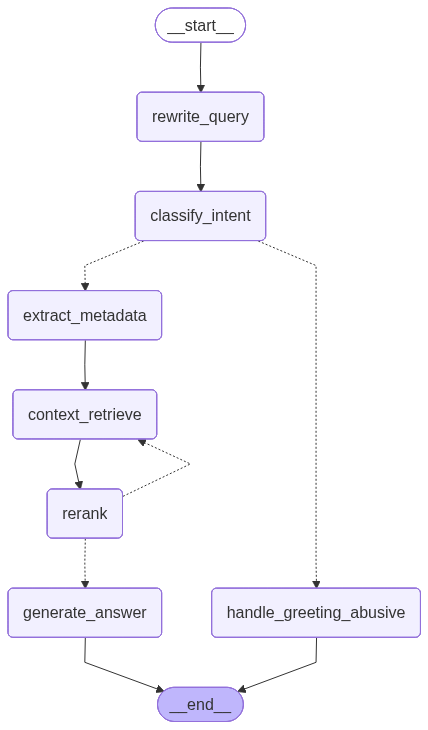

In [4]:
load_dotenv()

URL = "https://api.avalai.ir/v1"
OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')
llm = ChatOpenAI(base_url=URL, api_key=OPENAI_API_KEY, model="gpt-4o-mini", temperature=0.1)
embedding_model = SentenceTransformer('intfloat/multilingual-e5-small')


class AgentState(TypedDict):
    original_query: str
    rewritten_query: str
    intent: Literal["greeting", "abusive", "law_question"]
    intent_response: Optional[str]
    metadata_filter: Optional[Dict[str, Any]]
    retrieved_contexts: Optional[List[Document]]
    reranked_contexts: Optional[List[Document]]
    retrieval_attempts: int
    final_answer: Optional[str]


class MetadataQuery(BaseModel):
    doc_type: Optional[str] = Field(
        None, description="The type of legal document (e.g., 'قانون کار', 'تامین اجتماعی')."
    )
    article_number: Optional[int] = Field(
        None, description="Specific article number mentioned in the query."
    )
    has_note: Optional[bool] = Field(
        None, description="Whether the user is asking about notes/footnotes (تبصره)."
    )

class IntentClassifier(BaseModel):
    intent: Literal["Greeting", "Abusive", "Law Question"]


def rewrite_query_node(state):
    prompt = ChatPromptTemplate.from_template("""
    شما یک دستیار متخصص در بازنویسی سؤالات حقوقی هستید. سؤال کاربر را به گونه‌ای بازنویسی کنید که:
    1. ابهام‌های زبانی را برطرف کند
    2. لحن استاندارد و یکنواخت داشته باشد
    3. برای سیستم بازیابی اطلاعات (IR) بهینه باشد
    4. ساختار دستوری صحیح داشته باشد
    سؤال اصلی: {query}
    سؤال بازنویسی شده:
    """)

    chain = prompt | llm | StrOutputParser()
    response = chain.invoke({"query": state["original_query"]})

    return {"rewritten_query": response.content}


def classify_intent_node(state):
    parser = PydanticOutputParser(pydantic_object=IntentClassifier)
    prompt = ChatPromptTemplate.from_template("""
    سؤال کاربر را در یکی از این دسته‌ها طبقه‌بندی کنید: «greeting»، «Abusive»، «Law Question».
    «{format_instructions}\n\n»
    «سؤال: {query}»
    """)

    chain = prompt | llm | parser
    try:
        response = chain.invoke({"query": state["original_query"], "format_instructions": parser.get_format_instructions()})
        raw_intent = response.intent.lower()

        if "law" in raw_intent:
            intent = "law_question"
        else:
            intent = raw_intent
        return {"intent": intent}
    
    except:
        intent = "greeting"

    return {"intent": intent}


def extract_metadata_node(state):
    parser = PydanticOutputParser(pydantic_object=MetadataQuery)
    prompt = ChatPromptTemplate.from_template(
        "Extract structured metadata for filtering legal documents from this query.\n"
        "Identify the document type (e.g., 'قانون کار', 'تامین اجتماعی'), specific article numbers, or if it relates to notes (تبصره).\n"
        "{format_instructions}\n\n"
        "Query: {query}"
    )

    chain = prompt | llm | parser
    try:
        response = chain.invoke({"query": state["rewritten_query"], "format_instructions": parser.get_format_instructions()})
        filters = {k: v for k, v in response.dict().items() if v is not None}
    except Exception as e:
        print(f"Error extracting metadata: {e}")
        filters = {}

    return {"metadata_filter": filters}


def context_retrieve_node(state):
    query = state["rewritten_query"]
    filters = state["metadata_filter"]
    K = 10

    query_vector = embedding_model.encode("query: " + query, normalize_embeddings=True).tolist()
    lance_query = table.search(query_vector).limit(K)

    if filters:
        if "doc_type" in filters and filters["doc_type"]:
            lance_query = lance_query.where(f"doc_type = '{filters["doc_type"]}'", prefilter=True)

        if "article_number" in filters and filters["article_number"] is not None:
            lance_query = lance_query.where(f"ARRAY_CONTAINS(article_number, {filters["article_number"]})")

        if "chapter" in filters and filters["chapter"]:
            lance_query = lance_query.where(f"chapter = '{filters["chapter"]}'", prefilter=True)

        if "amendment_flags" in filters and filters["amendment_flags"]:
            lance_query = lance_query.where(f"amendment_flags = '{filters["amendment_flags"]}'", prefilter=True)
        
        if "has_note" in filters and filters["has_note"] is not None:
            if filters["has_note"]:
                lance_query = lance_query.where("amendment_flags LIKE '%تبصره%'", prefilter=True)
            else:
                lance_query = lance_query.where("amendment_flags NOT LIKE '%تبصره%' OR amendment_flags IS NULL", prefilter=True)

    results = lance_query.to_list()

    documents = []
    for r in results:
        doc = Document(
            page_content=r["text"][:1000],
            metadata={
                "doc_type": r.get("doc_type", "unknown"),
                "article_number": r.get("article_number", -1),
                "chapter": r.get("chapter", "None"),
                "amendment_flags": r.get("amendment_flags", "None"),
                "language": r.get("language", "fa")
            }
        )
        documents.append(doc)

    return {"retrieved_contexts": documents, "retrieval_attempts": state.get("retrieval_attempts", 0) + 1}


def rerank_node(state):
    contexts = state.get("retrieved_contexts", [])
    current_retrieval_attempts = state.get("retrieval_attempts", 0)

    if not contexts:
        print("No contexts retrieved for reranking.")
        if current_retrieval_attempts < 2:
            return {"metadata_filter": {}, "reranked_contexts": None}
        else:
            return {"reranked_contexts": []}

    query_embedding = embedding_model.encode(
        "query: " + state["rewritten_query"],
        normalize_embeddings=True
    ).reshape(1, -1)

    context_embeddings = []
    for doc in contexts:
        context_embedding = embedding_model.encode(
            "passage: " + doc.page_content[:500],
            normalize_embeddings=True
        )
        context_embeddings.append(context_embedding)

    if not context_embeddings:
        print("No embeddings generated for contexts.")
        if current_retrieval_attempts < 2:
            return {"metadata_filter": {}, "reranked_contexts": None}
        else:
            return {"reranked_contexts": []}

    context_embeddings = np.array(context_embeddings)
    similarities = cosine_similarity(query_embedding, context_embeddings)[0]

    ranked_indices = np.argsort(similarities)[::-1]
    ranked_contexts = [contexts[i] for i in ranked_indices]
    ranked_similarities = [similarities[i] for i in ranked_indices]

    relevance_threshold = 0.5
    top_n = 3

    if (not ranked_similarities or ranked_similarities[0] < relevance_threshold) and current_retrieval_attempts < 2:
        print(f"!!! Reranking suggests contexts are not relevant enough (max_sim={ranked_similarities[0] if ranked_similarities else 'N/A'}), attempting retry with cleared filters !!!")
        new_metadata_filter = {}
        return {"metadata_filter": new_metadata_filter, "reranked_contexts": None}

    final_reranked_contexts = ranked_contexts[:top_n]

    for i, (doc, sim) in enumerate(zip(final_reranked_contexts, ranked_similarities[:top_n])):
        doc.metadata["similarity_score"] = float(sim)
        doc.metadata["rank"] = i + 1

    return {"reranked_contexts": final_reranked_contexts}


def generate_answer_node(state):
    contexts = state.get("reranked_contexts", [])

    if not contexts:
        prompt = ChatPromptTemplate.from_template("""
        به سؤال کاربر با توجه به پایگاه داده پاسخ دهید.
        سؤال: {query}
        پاسخ را درصورتی که اطلاعاتی در پایگاه داده موجود نیست روشن بیان کنید که پاسخی وجود ندارد،
        پاسخ:
        """)

        chain = prompt | llm
        response = chain.invoke({"query": state["rewritten_query"]})
        return {"final_answer": response.content}

    context_texts = []
    for i, doc in enumerate(contexts):
        context_texts.append(
            f"[سند {i+1}] منبع: {doc.metadata.get('doc_name', 'ناشناخته')} (نوع: {doc.metadata.get('doc_type', 'ناشناخته')}, ماده: {doc.metadata.get('article_number', 'ناشناخته')})\n"
            f"محتوا: {doc.page_content[:800]}...\n"
            f"امتیاز ارتباط: {doc.metadata.get('similarity_score', 0):.2f}\n"
        )

    all_contexts = "\n".join(context_texts)

    prompt = ChatPromptTemplate.from_template("""
    شما یک وکیل هوشمند هستید. بر اساس اسناد حقوقی ارائه شده،
    به سؤال کاربر پاسخ دقیق و منسجم دهید.

    دستورالعمل‌ها:
    1. پاسخ باید بر اساس اسناد ارائه شده باشد
    2. اگر اطلاعات کافی در اسناد نیست، بیان کنید اطلاعاتی وجود ندارد
    3. از اصطلاحات حقوقی به درستی استفاده کنید
    4. پاسخ را به فارسی روان و ساده ارائه دهید
    5. در صورت لزوم، به مواد قانونی خاص اشاره کنید
    6. اگر اسناد متناقض باشند، آن را ذکر کنید
    سؤال کاربر: {query}
    اسناد مرتبط:
    {contexts}
    پاسخ نهایی:
    """)

    chain = prompt | llm
    response = chain.invoke({"query": state["rewritten_query"], "contexts": all_contexts})

    return {"final_answer": response.content}


def route_intent(state):
    intent = state.get("intent", "").lower()

    if intent == "greeting" or intent == "abusive":
        return "handle_greeting_abusive"
    elif intent == "law_question":
        return "extract_metadata"
    else:
        return "extract_metadata"

def handle_greeting_abusive(state):
    intent = state.get("intent", "").lower()

    if intent == "greeting":
        return {"final_answer": "سلام! من دستیار حقوقی هوشمند هستم. چطور می‌توانم به شما کمک کنم؟"}

    if intent == "abusive":
        return {"final_answer": "من یک مدل هوش مصنوعی هستم که برای پاسخگویی به سوالات حقوقی طراحی شده‌ام و وارد بحث‌های تنش‌زا نمی‌شوم. لطفاً سوال حقوقی خود را بپرسید."}


def generate_direct_response(state):
    return {"final_answer": state.get("intent_response", "")}

def route_retrieval(state):
    if state.get("reranked_contexts") is None:
        return "context_retrieve"
    else:
        return "generate_answer"

workflow = StateGraph(AgentState)

workflow.add_node("rewrite_query", rewrite_query_node)
workflow.add_node("classify_intent", classify_intent_node)
workflow.add_node("handle_greeting_abusive", handle_greeting_abusive)
workflow.add_node("extract_metadata", extract_metadata_node)
workflow.add_node("context_retrieve", context_retrieve_node)
workflow.add_node("rerank", rerank_node)
workflow.add_node("generate_answer", generate_answer_node)
workflow.set_entry_point("rewrite_query")
workflow.add_edge("rewrite_query", "classify_intent")
workflow.add_conditional_edges(
    "classify_intent",
    route_intent,
    {
        "handle_greeting_abusive": "handle_greeting_abusive",
        "extract_metadata": "extract_metadata"
    }
)
workflow.add_edge("extract_metadata", "context_retrieve")
workflow.add_edge("context_retrieve", "rerank")
workflow.add_conditional_edges(
    "rerank",
    route_retrieval,
    {
        "context_retrieve": "context_retrieve",
        "generate_answer": "generate_answer"
    }
)
workflow.add_edge("handle_greeting_abusive", END)
workflow.add_edge("generate_answer", END)

agent = workflow.compile()

def run_agent(query):
    initial_state = {
        "original_query": query,
        "rewritten_query": "",
        "intent": "",
        "intent_response": None,
        "metadata_filter": None,
        "retrieved_contexts": None,
        "reranked_contexts": None,
        "retrieval_attempts": 0,
        "llm": None,
        "final_answer": None
    }

    result = agent.invoke(initial_state)
    return result

display(Image(agent.get_graph().draw_mermaid_png()))

## 5. Agent Testing with Sample Queries

Runs a small battery of test queries covering greetings, abusive inputs, and legal questions across several law categories, and prints the intermediate state (rewritten query, intent, extracted metadata, retrieved/reranked documents) alongside the final answer.

In [5]:
test_queries = [
    "سلام، حالتون خوبه؟",
    "تو بی‌عرضه‌ترین رباتی هستی که دیدم!",
    "شرایط اعتراض به چک برگشتی چیست?",
    "قانون جدید کار در مورد مرخصی سالانه چه می‌گوید?",
    "موجر چه زمانی می‌تواند مستأجر را بیرون کند?",
    "ماده ده قانون سرقفلی"
]

for query in test_queries:
    print(f"\033[1mQuery:\033[0m {query}")

    result = run_agent(query)

    print(f"\n\033[1mRewriting Query:\033[0m {result.get('rewritten_query', '')}")
    print(f"\033[1mQuery Type:\033[0m {result.get('intent', '')}")

    if result.get('metadata_filter'):
        print(f"\033[1mExtracted metadata:\033[0m {result['metadata_filter']}")

    if result.get('retrieved_contexts'):
        print(f"\033[1mNumber of documents retrieved:\033[0m {len(result['retrieved_contexts'])}")

    if result.get('reranked_contexts'):
        print(f"\033[1mNumber of resorted documents:\033[0m {len(result['reranked_contexts'])}")
        for i, doc in enumerate(result['reranked_contexts'][:2]):
            print(f""" - Document {i+1}: {doc.metadata.get('source_file', '')} (Score: {doc.metadata.get('similarity_score', 0):.2f})""")

    if result.get('llm'):
        print(f"\033[1mLLM answer:\033[0m\n{result.get('llm', 'No answer from LLM')}")
        print(f"{'─'*60}")

    print(f"\033[1mFinal Response:\033[0m\n{result.get('final_answer', '')}")
    print(f"\n{'='*60}")


Query: سلام، حالتون خوبه؟

Rewriting Query: سلام، حالتون خوبه؟
Query Type: greeting
Final Response:
سلام! من دستیار حقوقی هوشمند هستم. چطور می‌توانم به شما کمک کنم؟

Query: تو بی‌عرضه‌ترین رباتی هستی که دیدم!

Rewriting Query: تو بی‌عرضه‌ترین رباتی هستی که دیدم!
Query Type: abusive
Final Response:
من یک مدل هوش مصنوعی هستم که برای پاسخگویی به سوالات حقوقی طراحی شده‌ام و وارد بحث‌های تنش‌زا نمی‌شوم. لطفاً سوال حقوقی خود را بپرسید.

Query: شرایط اعتراض به چک برگشتی چیست?

Rewriting Query: شرایط اعتراض به چک برگشتی چیست?
Query Type: law question
Number of documents retrieved: 10
Number of resorted documents: 3
 - Document 1:  (Score: 0.87)
 - Document 2:  (Score: 0.86)
Final Response:
شرایط اعتراض به چک برگشتی به طور کلی به موارد زیر بستگی دارد:

1. **حق شکایت کیفری**: طبق سند 1، شخصی که چک پس از برگشت از بانک به او منتقل شده، حق شکایت کیفری نخواهد داشت مگر اینکه انتقال چک به صورت قانونی و با رعایت شرایط لازم انجام شده باشد.

2. **شکایت علیه دستور عدم پرداخت**: بر اساس سند 3، دارنده چک می

## 6. Temporal Performance Analysis

Wraps every agent node with a timing decorator, runs 21 representative legal queries (3 per law category), and reports the per-node and total execution times. This is used to identify the system bottleneck.

In [9]:
execution_times = {}

def timing_decorator(node_name):
    def decorator(func):
        @wraps(func)
        def wrapper(state, *args, **kwargs):
            start_time = time.time()
            result = func(state, *args, **kwargs)
            end_time = time.time()

            query = state.get("original_query", "unknown")
            if query not in execution_times:
                execution_times[query] = {}

            execution_times[query][node_name] = {
                'start': start_time,
                'end': end_time,
                'duration': end_time - start_time
            }

            print(f" - Time: {end_time - start_time:.3f} seconds")
            return result
        return wrapper
    return decorator

original_rewrite_query_node = rewrite_query_node
original_classify_intent_node = classify_intent_node
original_extract_metadata_node = extract_metadata_node
original_context_retrieve_node = context_retrieve_node
original_rerank_node = rerank_node
original_generate_answer_node = generate_answer_node
original_handle_greeting_abusive = handle_greeting_abusive

@timing_decorator("rewrite_query")
def timed_rewrite_query_node(state):
    print("Rewriting Query")
    return original_rewrite_query_node(state)

@timing_decorator("classify_intent")
def timed_classify_intent_node(state):
    print("Classifing Intent")
    return original_classify_intent_node(state)

@timing_decorator("extract_metadata")
def timed_extract_metadata_node(state):
    print("Extracting Metadata")
    return original_extract_metadata_node(state)

@timing_decorator("context_retrieve")
def timed_context_retrieve_node(state):
    print("Retrieving Context")
    return original_context_retrieve_node(state)

@timing_decorator("rerank")
def timed_rerank_node(state):
    print("Reranking & Checking Relevance")
    return original_rerank_node(state)

@timing_decorator("generate_answer")
def timed_generate_answer_node(state):
    print("Generating Answer")
    return original_generate_answer_node(state)

@timing_decorator("handle_greeting_abusive")
def timed_handle_greeting_abusive(state):
    print("Handling Greeting/Abusive")
    return original_handle_greeting_abusive(state)

workflow_timing = StateGraph(AgentState)

workflow_timing.add_node("rewrite_query", timed_rewrite_query_node)
workflow_timing.add_node("classify_intent", timed_classify_intent_node)
workflow_timing.add_node("handle_greeting_abusive", timed_handle_greeting_abusive)
workflow_timing.add_node("extract_metadata", timed_extract_metadata_node)
workflow_timing.add_node("context_retrieve", timed_context_retrieve_node)
workflow_timing.add_node("rerank", timed_rerank_node)
workflow_timing.add_node("generate_answer", timed_generate_answer_node)
workflow_timing.set_entry_point("rewrite_query")
workflow_timing.add_edge("rewrite_query", "classify_intent")
workflow_timing.add_conditional_edges(
    "classify_intent",
    route_intent,
    {
        "handle_greeting_abusive": "handle_greeting_abusive",
        "extract_metadata": "extract_metadata"
    }
)
workflow_timing.add_edge("extract_metadata", "context_retrieve")
workflow_timing.add_edge("context_retrieve", "rerank")
workflow_timing.add_conditional_edges(
    "rerank",
    route_retrieval,
    {
        "context_retrieve": "context_retrieve",
        "generate_answer": "generate_answer"
    }
)
workflow_timing.add_edge("handle_greeting_abusive", END)
workflow_timing.add_edge("generate_answer", END)

agent_test = workflow_timing.compile()

def run_agent_with_timing(query):
    print(f"\033[1mQuery:\033[0m {query}")

    initial_state = {
        "original_query": query,
        "rewritten_query": "",
        "intent": "",
        "intent_response": None,
        "metadata_filter": None,
        "retrieved_contexts": None,
        "reranked_contexts": None,
        "retrieval_attempts": 0,
        "llm": None,
        "final_answer": None
    }

    start_total = time.time()
    result = agent_test.invoke(initial_state)
    end_total = time.time()

    if query not in execution_times:
        execution_times[query] = {}
    execution_times[query]['total'] = {
        'start': start_total,
        'end': end_total,
        'duration': end_total - start_total
    }

    print(f"\n\033[1m + Total execution time:\033[0m {end_total - start_total:.3f} seconds")
    print(f"\033[1mAnswer:\033[0m {str(result['final_answer'])[:100]}...\n\n")

    return result


test_queries = [
    #  قانون کار
    "طبق مقررات، حداکثر مدت زمانی که یک کارگر در طول یک هفته باید کار کند بر اساس ماده ۵۱ قانون کار چقدر تعیین شده است؟",
    "مرخصی سالانه ای که هر کارگر می تواند با در نظر گرفتن روزهای تعطیل هفته استفاده کند، چند روز می باشد؟",
    "به موجب ماده ۷۹ قانون کار، افراد از چه سنی مجاز به ورود به بازار کار و عقد قرارداد کاری می شوند؟",

    #  قانون چک
    "شاکی چک برگشتی برای طرح شکایت کیفری، تا چه مدت پس از تاریخ گواهی عدم پرداخت فرصت دارد؟",
    "آیا نوشتن چک هایی که تاریخ وصول آن در آینده است، تبعات جزایی و مجازات قانونی در پی دارد؟",
    "در صورتی که موجودی حساب فرد صادرکننده چک کافی نباشد، بانک بر اساس قانون چه اقدامی باید انجام دهد؟",

    #  قانون مالیات بر ارزش افزوده
    "طبق اصول قانون مالیات بر ارزش افزوده، چه شخص یا گروهی به عنوان تحمل کننده نهایی این مالیات شناخته می شود؟",
    "آیا ارائه خدمات مرتبط با درمان و بهداشت، از پرداخت مالیات بر ارزش افزوده معاف می باشند؟",
    "در صورت خودداری فعالان اقتصادی از ارائه فاکتور یا صورتحساب رسمی، چه نوع جریمه ای برای آنها در نظر گرفته شده است؟",

    #  قانون روابط موجر و مستأجر
    "به موجب قانون سال ۱۳۷۶، برای رسمیت یافتن قرارداد اجاره، امضاء چند نفر به عنوان شاهد الزامی است؟",
    "پس از ابلاغ حکم تخلیه، ماموران اجرای قانون حداکثر چقدر وقت دارند تا دستور را عملی کنند؟",
    "موجر در چه شرایطی مجاز است قبل از پایان مدت قرارداد، آن را فسخ و درخواست تخلیه ملک را نماید؟",

    #  قانون تأمین اجتماعی
    "بر اساس ماده ۲۸ قانون تأمین اجتماعی، درصدی که کارفرما ملزم به پرداخت آن به عنوان حق بیمه می باشد، چقدر است؟",
    "برای آنکه یک مرد واجد شرایط دریافت مستمری بازنشستگی شود، داشتن چه سابقه ای از پرداخت حق بیمه لازم است؟",
    "یک کارگر که اخراج شده است، برای برخورداری از مزایای بیمه بیکاری باید دارای چه ویژگی اصلی باشد؟",

    #  قانون ثبت اسناد و املاک
    "اگر سندی مشمول ثبت باشد اما به ثبت نرسد، در مراجع و دستگاه های دولتی از چه اعتباری برخوردار خواهد بود؟",
    "افراد برای اعتراض به ثبت یک ملک، پس از انتشار آگهی ثبتی در نوبت معین، چه مدت فرصت دارند؟",
    "در مراجع قضایی، چه تفاوت اساسی بین سندی که رسمی است و سندی که به صورت عادی تنظیم شده، وجود دارد؟",

    #  قانون مبارزه با قاچاق کالا و ارز
    "به موجب قانون، برای شخصی که مبادرت به نگهداری کالاهای ممنوعه قاچاق کند، چه مجازاتی پیش بینی شده است؟",
    "رسیدگی به جرایم قاچاق که به صورت سازمان یافته و حرفه ای انجام می شود، در صلاحیت کدام مرجع قانونی است؟",
    "آیا وسیله نقلیه ای که برای جابجایی کالای قاچاق مورد استفاده قرار گرفته، بر اساس حکم قانون توقیف یا ضبط می شود؟"
]

results = []
for query in test_queries:
    result = run_agent_with_timing(query)
    results.append(result)

print("\n" + "_"*80)
print("\033[1mAnalysis of execution time of each node\033[0m")
print("_"*80)

analysis_data = []
for query, timings in execution_times.items():
    if query == 'unknown':
        continue

    row = {'Query': query}
    total_time = timings.get('total', {}).get('duration', 0)

    for node_name in ['rewrite_query', 'classify_intent', 'extract_metadata',
                     'context_retrieve', 'rerank', 'generate_answer']:
        if node_name in timings:
            row[node_name] = timings[node_name]['duration']
        else:
            row[node_name] = 0

    row['total'] = total_time
    analysis_data.append(row)

df = pd.DataFrame(analysis_data)
print(df)

print("\n\033[1mAverage execution time per node:\033[0m")
mean_times = df.mean(numeric_only=True)
for node, time_avg in mean_times.items():
    if node != 'total':
        print(f"{node}: {time_avg:.3f} seconds")

print(f"\n\033[1mAverage total time:\033[0m {mean_times['total']:.3f} seconds")

max_avg_node = mean_times.drop('total').idxmax()
print(f"\n\033[1mMain system bottleneck:\033[0m {max_avg_node} with an average of {mean_times[max_avg_node]:.3f} seconds")


Query: طبق مقررات، حداکثر مدت زمانی که یک کارگر در طول یک هفته باید کار کند بر اساس ماده ۵۱ قانون کار چقدر تعیین شده است؟
Rewriting Query
 - Time: 1.422 seconds
Classifing Intent
 - Time: 0.733 seconds
Extracting Metadata
 - Time: 1.015 seconds
Retrieving Context
 - Time: 0.168 seconds
Reranking & Checking Relevance
 - Time: 0.587 seconds
Generating Answer
 - Time: 2.280 seconds

 + Total execution time: 6.227 seconds
Answer: طبق ماده ۵۱ قانون کار، ساعات کار کارگران در شبانه‌روز نباید از ۸ ساعت تجاوز کند. بنابراین، حداکثر مد...


Query: مرخصی سالانه ای که هر کارگر می تواند با در نظر گرفتن روزهای تعطیل هفته استفاده کند، چند روز می باشد؟
Rewriting Query
 - Time: 1.053 seconds
Classifing Intent
 - Time: 0.872 seconds
Extracting Metadata
 - Time: 0.868 seconds
Retrieving Context
 - Time: 0.098 seconds
Reranking & Checking Relevance
 - Time: 2.903 seconds
Generating Answer
 - Time: 3.269 seconds

 + Total execution time: 9.075 seconds
Answer: بر اساس اسناد ارائه شده، مرخصی استحقاقی سالانه ک

## 7. Execution Time Visualization

Plots the average execution time of each agent node as a bar chart to make the bottleneck visually obvious.

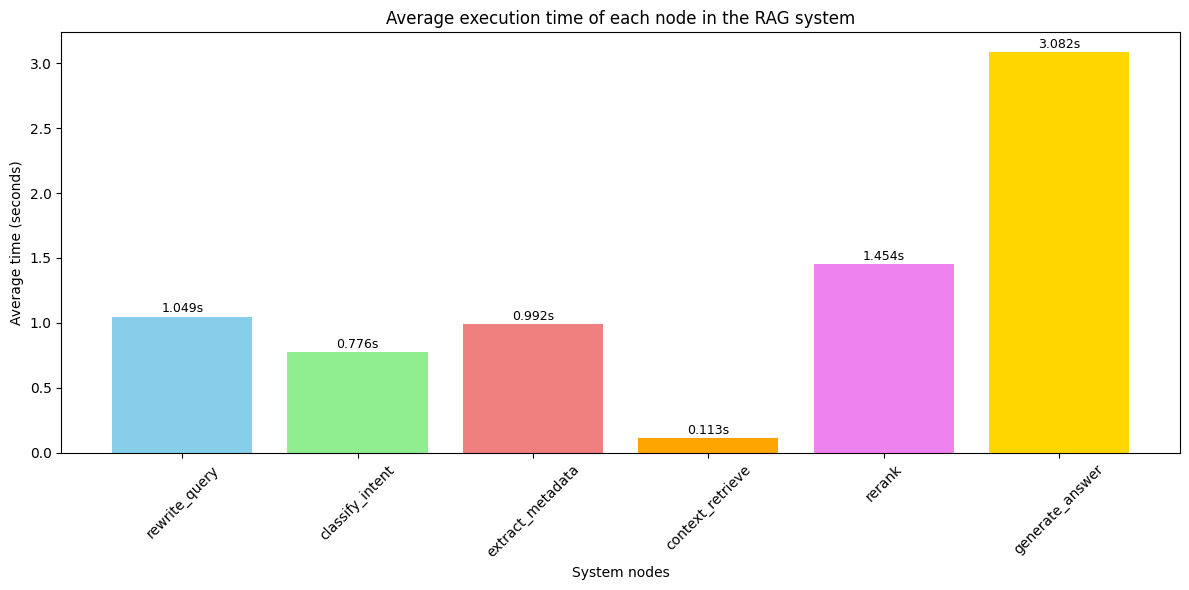

In [10]:
plt.figure(figsize=(12, 6))
nodes = ['rewrite_query', 'classify_intent', 'extract_metadata', 'context_retrieve', 'rerank', 'generate_answer']
avg_times = [mean_times[node] for node in nodes]
bars = plt.bar(nodes, avg_times, color=['skyblue', 'lightgreen', 'lightcoral', 'orange', 'violet', 'gold'])
plt.xlabel('System nodes')
plt.ylabel('Average time (seconds)')
plt.title('Average execution time of each node in the RAG system')
plt.xticks(rotation=45)
plt.tight_layout()

for bar, time_val in zip(bars, avg_times):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{time_val:.3f}s', ha='center', va='bottom', fontsize=9)

plt.show()


<div dir='rtl' style='background:#fffbe6; font-family: Vazir; border:1px dashed #f0ad4e; padding:12px; border-radius:8px; color:#111'>
✍️ <b>پاسخ تشریحی:</b><br>
<b>شناسایی و تحلیل گلوگاه</b><br>
نود generate_answer با زمان اجرای متوسط 3.082 ثانیه، به‌عنوان گلوگاه اصلی سیستم است. با توجه به سرعت اینترنت در اجرا آخرین بار زمان تولید این نود بین 0.24 الی 7.68 ثانیه متغییر بود. این نود تقریبا 35% از کل زمان اجرای پایپ‌لاین را به خود اختصاص داده است. علت اصلی این تأخیر به عوامل متعددی مربوط می‌شود که از جمله آن می¬توان به موارد زیر اشاره کرد:<br>
•	استفاده از مدل زبان سنگین: مدل GPT-4o-mini اگرچه دقیق‌تر است، اما زمان پردازش قابل‌توجهی نیاز دارد.<br>
•	حجم بالای داده‌های ورودی: ارسال متون کامل سه سند همراه با متادیتاها باعث افزایش حجم توکن‌های ارسالی به مدل می‌شود.<br>
•	پرامت¬های سنگین: وجود دستورالعمل‌های طولانی با ساختار پیچیده در پرامت باعث طولانی شدن زمان پردازش مدل شده است ولی از طرفی نیز باعث بهبود کیفیت جواب شده است.<br>
•	تأخیرهای شبکه: ارتباط با API خارجی و استفاده از مدل زبانی روی سایر سرویس دهنده‌ها باعث شده است زمان ارسال کوئری و دریافت جواب سهم قابل‌توجهی در این تأخیر دارد.<br>

<b>راهکارهای بهبود عملکرد</b><br>
برای کاهش تأخیر سیستم، راهکارهای زیر پیشنهاد می‌شود:<br>
•	جایگزینی مدل زبان: استفاده از مدل¬های سبک¬تر مثل استفاده از GPT-3.5-turbo که تا ۶۰ درصد سریع‌تر از GPT-4o-mini عمل می‌کند، می‌تواند زمان پاسخ‌دهی را به مقدار قابل توجهی کاهش دهد.<br>
•	کاهش حجم محتوا: محدود کردن تعداد اسناد ارسالی از ۳ به ۲ سند و فشرده‌سازی محتوای هر سند به ۲۰۰ کاراکتر، حجم داده‌های ورودی را به‌طور چشمگیری کاهش می‌دهد.<br>
•	بهینه‌سازی پرامت: بازنویسی دستورالعمل‌ها به صورت مختصر و حذف بخش‌های غیرضروری. که البته روی کیفیت پاسخ ممکن است تاثیرگذار باشد.<br>
•	پیاده‌سازی سیستم کش: ایجاد مکانیسم کش‌گذاری هوشمند برای ذخیره پاسخ‌های پرتکرار که می‌تواند تا ۴۰ درصد از درخواست‌ها را بدون فراخوانی مدل زبان پاسخ دهد.<br>
•	موازی‌سازی مراحل: اجرای همزمان نودهای مستقل مانند context_retrieve و extract_metadata که وابستگی به یکدیگر ندارند.<br>
•	استریمینگ پاسخ‌ها: نمایش تدریجی پاسخ به کاربر به جای انتظار برای تولید کامل پاسخ.<br>
•	تقسیم بار هوشمند: استفاده از مدل‌های مختلف بر اساس پیچیدگی سؤال (مدل‌های سبک‌تر برای سؤالات ساده و مدل‌های قوی‌تر برای موارد پیچیده).<br>
•	Fine-tuning مدل اختصاصی: آموزش یک مدل سبک‌وزن مخصوص دامنه حقوقی که هم سریع‌تر است و هم دقت بالاتری در این حوزه دارد.<br>
•	معماری توزیع‌شده: تقسیم بار پردازش بین چندین سرور و استفاده از تکنیک‌های Load Balancing.<br>


</div>


## 8. RAG Quality Evaluation with RAGAS

Builds a 21-question evaluation dataset (3 per law category) with expected answers, runs the agent on each query, and computes the RAGAS metrics **Faithfulness** and **Answer Relevancy**. The per-query results are saved to Excel files for further inspection.

In [ ]:
ragas_embeddings = HuggingFaceEmbeddings(model_name="intfloat/multilingual-e5-small")
ragas_data = { "query": [], "gold": [], "response": [], "contexts": [], "user_input": [] }
test_data = [
    #  قانون مبارزه با قاچاق كالا و ارز
    {
        "query": "تعریف قاچاق کالا و ارز چیست؟",
        "response": "هر فعل یا ترک فعلی که موجب نقض تشریفات قانونی ورود و خروج کالا و ارز گردد (ماده 1).",
        "documentation": "نسخه چاپی قانون مباربه با قاچاق كالا و ارز.pdf"
    },
    {
        "query": "مرجع رسیدگی به جرایم قاچاق سازمان یافته کجاست?",
        "response": "در صلاحیت دادسرا و دادگاه انقلاب است.",
        "documentation": "نسخه چاپی قانون مباربه با قاچاق كالا و ارز.pdf"
    },
    {
        "query": "مجازات نگهداری کالای قاچاق چیست?",
        "response": "علاوه بر ضبط کالا، جریمه نقدی معادل چند برابر ارزش کالا دریافت می‌شود.",
        "documentation": "نسخه چاپی قانون مباربه با قاچاق كالا و ارز.pdf"
    },

    #  قانون ثبت اسناد و املاك
    {
        "query": "آیا ثبت املاک اجباری است?",
        "response": "بله، در نقاطی که اداره ثبت آگهی می‌کند، ثبت کلیه اموال غیرمنقول اجباری است (ماده 46/47).",
        "documentation": "نسخه چاپی قانون ثبت اسناد و املاك.pdf"
    },
    {
        "query": "اعتبار اسناد ثبت نشده در دادگاه‌ها چگونه است?",
        "response": "طبق ماده 48، سندی که باید به ثبت برسد و نرسیده، در هیچ‌یک از ادارات و محاکم پذیرفته نخواهد شد.",
        "documentation": "نسخه چاپی قانون ثبت اسناد و املاك.pdf"
    },
    {
        "query": "تفاوت سند رسمی با عادی چیست?",
        "response": "سند رسمی لازم‌الاجرا است و انکار و تردید نسبت به آن مسموع نیست (فقط ادعای جعل).",
        "documentation": "نسخه چاپی قانون ثبت اسناد و املاك.pdf"
    },

    #  قانون تأمين اجتماعي
    {
        "query": "نرخ حق بیمه سهم کارگر و کارفرما چقدر است?",
        "response": "طبق ماده 28، حق بیمه 30٪ مزد است: 7٪ سهم بیمه شده، 20٪ سهم کارفرما و 3٪ کمک دولت.",
        "documentation": "نسخه چاپی قانون تأمين اجتماعي.pdf"
    },
    {
        "query": "شرایط استفاده از بیمه بیکاری چیست?",
        "response": "بیمه‌شده باید بدون میل و اراده بیکار شده و آماده به کار باشد و سابقه پرداخت حق بیمه داشته باشد.",
        "documentation": "نسخه چاپی قانون تأمين اجتماعي.pdf"
    },
    {
        "query": "سن بازنشستگی برای مردان چقدر است?",
        "response": "طبق ماده 76، شصت سال سن برای مردان مشروط بر داشتن حداقل سابقه پرداخت حق بیمه.",
        "documentation": "نسخه چاپی قانون تأمين اجتماعي.pdf"
    },

    #  قانون روابط موجر و مستأجر
    {
        "query": "شرایط تخلیه فوری ملک در قانون چیست?",
        "response": "قرارداد باید رسمی یا با امضای دو شاهد باشد و مدت اجاره منقضی شده باشد.",
        "documentation": "نسخه چاپی قانون روابط موجر و مستأجر_page-0001.pdf"
    },
    {
        "query": "مهلت اجرای دستور تخلیه چقدر است?",
        "response": "پس از ابلاغ دستور قضایی، ظرف مدت یک هفته اجرا می‌شود.",
        "documentation": "نسخه چاپی قانون روابط موجر و مستأجر_page-0001.pdf"
    },
    {
        "query": "آیا مستأجر حق دریافت سرقفلی را دارد?",
        "response": "تنها در صورتی که در ابتدای اجاره مبلغی به عنوان سرقفلی پرداخت کرده باشد، به نرخ روز دریافت می‌کند.",
        "documentation": "نسخه چاپی قانون روابط موجر و مستأجر_page-0001.pdf"
    },

    #  قانون ماليات بر ارزش افزوده
    {
        "query": "تعریف «عرضه کالا» در قانون مالیات بر ارزش افزوده چیست?",
        "response": "طبق ماده 1، واگذاری کالا یا ارائه خدمت به غیر، از طریق ھر نوع معامله یا عقد قانونی.",
        "documentation": "نسخه چاپی قانون ماليات بر ارزش افزوده.pdf"
    },
    {
        "query": "آیا محصولات کشاورزی فرآوری نشده مشمول مالیات هستند?",
        "response": "خیر، طبق قانون، عرضه محصولات کشاورزی فرآوری نشده از پرداخت مالیات و عوارض معاف است.",
        "documentation": "نسخه چاپی قانون ماليات بر ارزش افزوده.pdf"
    },
    {
        "query": "مهلت تسلیم اظهارنامه مالیات بر ارزش افزوده چه زمانی است?",
        "response": "معمولاً 15 روز پس از پایان هر فصل (دوره مالیاتی) است.",
        "documentation": "نسخه چاپی قانون ماليات بر ارزش افزوده.pdf"
    },

    #  قانون صدور چك
    {
        "query": "مهلت قانونی برای شکایت کیفری چک برگشتی چقدر است?",
        "response": "دارنده چک باید ظرف ۶ ماه از تاریخ صدور گواهی عدم پرداخت شکایت نماید.",
        "documentation": "نسخه چاپی قانون صدور چك_page-0001.pdf"
    },
    {
        "query": "مجازات صدور چک بلامحل چیست?",
        "response": "بسته به مبلغ، حبس تعزیری و ممنوعیت از داشتن دسته چک (طبق قانون اصلاحی).",
        "documentation": "نسخه چاپی قانون صدور چك_page-0001.pdf"
    },
    {
        "query": "آیا چک تضمینی قابل تعقیب کیفری است?",
        "response": "خیر، صدور چک به عنوان تضمین یا چک سفید امضا فاقد جنبه کیفری است.",
        "documentation": "نسخه چاپی قانون صدور چك_page-0001.pdf"
    },

    #  قانون كار
    {
        "query": "طبق مقررات، حداکثر مدت زمانی که یک کارگر در طول یک هفته باید کار کند بر اساس ماده ۵۱ قانون کار چقدر تعیین شده است?",
        "response": "طبق ماده 51 قانون کار، ساعات کار عادی کارگران نباید از 44 ساعت در هفته تجاوز کند.",
        "documentation": "نسخه چاپی قانون كار.pdf"
    },
    {
        "query": "میزان مرخصی استحقاقی سالانه کارگران چقدر است?",
        "response": "طبق ماده 64، مرخصی استحقاقی سالانه با استفاده از مزد و احتساب چهار روز جمعه، جمعاً یک ماه است.",
        "documentation": "نسخه چاپی قانون كار.pdf"
    },
    {
        "query": "مرجع تعیین حداقل دستمزد کارگران کیست?",
        "response": "طبق ماده 41، شورای عالی کار موظف است همه ساله میزان حداقل مزد کارگران را تعیین نماید.",
        "documentation": "نسخه چاپی قانون كار.pdf"
    }
]

def run_agent(query):
    initial_state = {
        "original_query": query,
        "rewritten_query": "",
        "intent": "",
        "intent_response": None,
        "metadata_filter": None,
        "retrieved_contexts": None,
        "reranked_contexts": None,
        "retrieval_attempts": 0,
        "llm": None,
        "final_answer": None
    }

    result = agent.invoke(initial_state)
    return result

for i, item in enumerate(test_data):
    query = item["query"]
    true_response = item["response"]
    print(f"Query number {i+1}: {query}")
    ragas_data["query"].append(query)
    ragas_data["gold"].append(true_response)
    ragas_data["user_input"].append(query)

    try:
        result = run_agent(query)
        agent_answer = result["final_answer"]
        retrieved_texts = [doc.page_content for doc in result["reranked_contexts"]]
    except Exception as e:
        print(f"Error query number {i+1}: {e}")
        agent_answer = "Error"
        retrieved_texts = ["No context."]

    ragas_data["response"].append(agent_answer)
    ragas_data["contexts"].append(retrieved_texts)

dataset = Dataset.from_dict(ragas_data)
criteria_results = evaluate(
    dataset=dataset,
    metrics=[faithfulness, answer_relevancy],
    llm=llm,
    embeddings=ragas_embeddings
)

avarage_faithfulness = sum(criteria_results['faithfulness']) / len(criteria_results['faithfulness'])
avarage_answer_relevancy = sum(criteria_results['answer_relevancy']) / len(criteria_results['answer_relevancy'])
print(f"Faithfulness Criteria: {avarage_faithfulness:.4f}")
print(f"Answer Relevancy Criteria: {avarage_answer_relevancy:.4f}")

df = criteria_results.to_pandas()
df.to_excel("criteria_results.xlsx", index=False)
print("Criteria results saved to criteria_results.xlsx")

# The code below has not been executed (because the internet was down last day), but it displays more information and saves it to an Excel file.
output_df = pd.DataFrame({
    "query": ragas_data["query"],
    "gold_answer": ragas_data["gold"],
    "agent_answer": ragas_data["response"],
    "retrieved_contexts": ["\n---\n".join(ct) for ct in ragas_data["contexts"]],
    "faithfulness": criteria_results["faithfulness"],
    "answer_relevancy": criteria_results["answer_relevancy"]
})
output_df.to_excel("evaluation_results.xlsx", index=False)


Query number 1: تعریف قاچاق کالا و ارز چیست؟
Query number 2: مرجع رسیدگی به جرایم قاچاق سازمان یافته کجاست?
Query number 3: مجازات نگهداری کالای قاچاق چیست?
Query number 4: آیا ثبت املاک اجباری است?
Query number 5: اعتبار اسناد ثبت نشده در دادگاه‌ها چگونه است?
Query number 6: تفاوت سند رسمی با عادی چیست?
Query number 7: نرخ حق بیمه سهم کارگر و کارفرما چقدر است?
Query number 8: شرایط استفاده از بیمه بیکاری چیست?
Query number 9: سن بازنشستگی برای مردان چقدر است?
Query number 10: شرایط تخلیه فوری ملک در قانون چیست?
Query number 11: مهلت اجرای دستور تخلیه چقدر است?
Query number 12: آیا مستأجر حق دریافت سرقفلی را دارد?
Query number 13: تعریف «عرضه کالا» در قانون مالیات بر ارزش افزوده چیست?
Query number 14: آیا محصولات کشاورزی فرآوری نشده مشمول مالیات هستند?
Query number 15: مهلت تسلیم اظهارنامه مالیات بر ارزش افزوده چه زمانی است?
Query number 16: مهلت قانونی برای شکایت کیفری چک برگشتی چقدر است?
Query number 17: مجازات صدور چک بلامحل چیست?
Query number 18: آیا چک تضمینی قابل تعقیب کیفری است?

Evaluating:   0%|          | 0/42 [00:00<?, ?it/s]

Faithfulness Criteria: 0.6714
Answer Relevancy Criteria: 0.5415
Criteria results saved to criteria_results.xlsx


<div dir='rtl' style='background:#fffbe6; font-family: Vazir; border:1px dashed #f0ad4e; padding:12px; border-radius:8px; color:#111'>
✍️ <b>پاسخ تشریحی:</b><br>
<b>گزارش تحلیلی ارزیابی سیستم RAG با استفاده از معیارهای faithfulness و answer_relevancy</b><br>
در این ارزیابی، عملکرد یک RAG برای ۲۱ پرسش حقوقی از شش حوزه قانونی مختلف، با بهره‌گیری از کتابخانه RAGAS و دو معیار faithfulness و answer_relevancy سنجیده شد. میانگین وفاداری ۶۷۱۴/۰ و میانگین ارتباط پاسـخ ۵۴۱۵/۰ به‌دست آمد که نشان‌دهنده چالش‌هایی جدی در هر دو بعد صحت و مرتبط‌بودن است.<br>
<br>
<b>تحلیل معیار وفاداری (Faithfulness)</b><br>
این معیار می‌سنجد که آیا ادعاهای موجود در پاسخ، مستقیماً توسط متن‌های بازیابی‌شده پشتیبانی می‌شوند یا خیر. میانگین ۶۷/۰ نشان می‌دهد که نزدیک به یک‌سوم محتوای پاسخ‌ها، استنتاج‌هایی فراتر از متون بازیابی‌شده یا حتی نادرست بوده‌اند. بیشترین معیار Faithfulness که یک است در پرسش‌های «مهلت اجرای دستور تخلیه»، «حق دریافت سرقفلی» و «مرجع تعیین حداقل دستمزد» (کوئری‌های شماره 11، 12 و 21) مشاهده می‌شود؛ زیرا پاسخ‌ها مستقیماً از ماده قانونی موجود در بسترها نقل شده‌اند. در مقابل، کمترین معیار Faithfulness که صفر است مربوط به «تفاوت سند رسمی با عادی» (کوئری شماره 6) است. پاسخ به تفصیل ویژگی‌های هر دو سند را شرح داده، اما هیچ‌یک از سه قطعه بازیابی‌شده چنین اطلاعاتی را در بر نداشته‌اند و سیستم محتوای را تولید کرده که با مستندات یکسان نبوده است. موارد مشابه با وفاداری اندک (۳۳/۰ تا ۴۳/۰) نظیر «اعتبار اسناد ثبت‌نشده»، «مرجع رسیدگی به قاچاق سازمان‌یافته» و «حداکثر ساعت کار هفتگی» (کوئرهای شماره 2، 5 و 19) نیز از همین الگو پیروی می‌کنند. بازیابی ضعیف (حضور متون نامرتبط) و سپس تلاش عامل برای تکمیل پاسخ با معلومات درونی یا استنباط‌های نادرست از اسناد مرتبط. همچنین در پرسش «مهلت تسلیم اظهارنامه ارزش افزوده» (کوئری شماره 15) با وفاداری ۵/۰، پاسخ به‌درستی «حداکثر یک ماه» را ذکر کرده، ولی در ادامه توضیحی اضافه دارد که از متون اسناد استخراج نشده است.<br>
<br>
<b>تحلیل معیار ارتباط پاسخ با پرسش (Answer Relevancy)</b><br>
این معیار با تبدیل پاسخ به یک پرسش فرضی و سنجش شباهت آن با پرسش اصلی، میزان مرتبط‌بودن پاسخ را کمی می‌کند. میانگین ۵۴/۰ نشان‌دهنده عملکرد ضعیف در این حوزه است. نکته چشمگیر، امتیاز صفر برای شش پرسش (کوئری‌های شماره ۱۲، ۱۳، ۱۵، ۱۸، ۱۹، ۲۰) است، در حالی که پاسخ‌های ارائه‌شده از نظر انسانی کاملاً مرتبط و حاوی اطلاعات درست هستند. (برای نمونه، پرسش درباره سرقفلی، عرضه کالا، مهلت اظهارنامه، تعقیب کیفری چک تضمینی، ساعت کار هفتگی و مرخصی سالانه). این صفرهای مطلق را نمی‌توان ناشی از نامرتبط‌بودن محتوایی دانست؛ بلکه احتمالاً به مشکل فنی در فرایند محاسبه بازمی‌گردد. بررسی نمونه‌های دارای امتیاز relevancy غیرصفر (مثلاً ۸۶/۰ تا ۹۷/۰) نشان می‌دهد که مدل تعبیه‌ساز (intfloat/multilingual-e5-small) به‌طور کلی توانایی پردازش فارسی را دارد. بنابراین صفرشدن امتیاز در این شش مورد می‌تواند دلایل زیر را داشته باشد:<br>
•	وجود کاراکتر‌های کنترلی (نظیر \u202b , \uf079) در رشته‌های پاسخ که ممکن است پیش‌پردازش کتابخانه را دچار اختلال کرده باشد.<br>
•	طولانی بودن بیش از حد پاسخ‌ها و ازدست‌رفتن انسجام معنایی در تولید پرسش معکوس.<br>
•	خطا در پیاده‌سازی حلقه ارزیابی (برای مثال عدم تخصیص درست ستون‌ها در Dataset یا تداخل با مقادیر None).<br>
•	در هر حال این نقص، تحلیل relevancy را با ابهام مواجه می‌کند و ضرورت بازبینی کد ارزیابی را یادآور می‌شود.<br>
<br>
<b>علت‌یابی خطاهای محتوایی</b><br>
با مقایسه پاسخ‌های تولیدشده و متن‌های بازیابی‌شده، سه الگوی خطای اصلی نمایان می‌شود:<br>
•	بازیابی نامرتبط یا ناکافی: در پرسش‌های مربوط به «قانون کار» (ساعات کار، مرخصی، دستمزد) قطعات بازیابی‌شده عمدتاً شامل مواد قانونی نامرتبط (ماده ۵۱ درباره آیین دادرسی یا بودجه) هستند که منجر به پاسخ‌گویی بر اساس حافظه مدل و کاهش وفاداری شده است.<br>
•	استنتاج نادرست از متون درست: در پرسش «مجازات نگهداری کالای قاچاق» پاسخ به درستی جریمه نقدی و ضبط کالا را بیان می‌کند، ولی جزئیات مربوط به حبس (برای مشروبات الکلی) را از متنی استخراج کرده که مربوط به محصولات ممنوعه خاص است و به‌طور کلی تعمیم داده شده؛ این امر وفاداری را از ۱ به ۸۳/۰ کاهش داده است.<br>
•	تزریق اطلاعات عمومی خارج از محتوا: در پرسش «شرایط بیمه بیکاری» پاسخ به ذکر اشتغال قبلی و درمان بسنده کرده، ولی فاقد پشتیبانی متنی برای «بیکارشدن بدون میل و اراده» است؛ مدل این شرط را از دانش خود افزوده است.<br>
<br>
میانگین امتیاز وفاداری ۶۷/۰ نشان می‌دهد که سیستم در حدود یک‌سوم مواقع به تولید محتوای نامستند روی می‌آورد که خطر پاسخ‌های نادرست یا گمراه‌کننده را افزایش می‌دهد. مشکل relevancy هرچند تحت تأثیر خطاهای محاسباتی پنهان شده، اما مقادیر غیرصفر نیز اغلب بین ۸۲/۰ تا ۸۷/۰ هستند که قابل قبول ولی نه عالی است. برای بهبود عملکرد می‌توان:<br>
•	بازیابی را هدفمندتر کرد – استفاده از رتبه‌بندهای قوی‌تر یا افزودن فیلترهای معنایی برای حذف قطعات کاملاً نامرتبط.<br>
•	پاسخ‌دهی را به متون محدود نمود – با دستورالعمل‌های صریح‌تر به مدل زبانی مبنی بر استناد انحصاری به زمینه و پرهیز از استنباط شخصی.<br>
•	پایپلاین ارزیابی را از نظر فنی پالایش داد – اطمینان از پاک‌سازی نویسه‌های خاص و بررسی صحت عملکرد معیار relevancy در محیط فارسی.<br>
•	مجموعه داده ارزیابی را با چک‌لیست دستی تطبیق داد – تا علاوه بر امتیاز خودکار، میزان تطابق پاسخ‌ها با «پاسخ صحیح مورد انتظار» (gold) نیز به‌عنوان معیار تکمیلی سنجیده شود.<br>
</div>


## 9. Bonus: Chainlit Interactive UI

Writes a Chainlit `app.py` that exposes the LangGraph agent as a conversational web app, then launches it with `chainlit run app.py -w`.

In [ ]:
%%writefile app.py

import lancedb
import numpy as np
import chainlit as cl
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, END
from langchain_core.documents import Document
from sentence_transformers import SentenceTransformer
from langchain_core.prompts import ChatPromptTemplate
from sklearn.metrics.pairwise import cosine_similarity
from typing import List, TypedDict, Optional, Dict, Any, Literal
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser


load_dotenv()

URL = "https://api.avalai.ir/v1"
OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')
llm = ChatOpenAI(base_url=URL, api_key=OPENAI_API_KEY, model="gpt-4o-mini", temperature=0.1)
embedding_model = SentenceTransformer('intfloat/multilingual-e5-small')


class AgentState(TypedDict):
    original_query: str
    rewritten_query: str
    intent: Literal["greeting", "abusive", "law_question"]
    intent_response: Optional[str]
    metadata_filter: Optional[Dict[str, Any]]
    retrieved_contexts: Optional[List[Document]]
    reranked_contexts: Optional[List[Document]]
    retrieval_attempts: int
    final_answer: Optional[str]


class MetadataQuery(BaseModel):
    doc_type: Optional[str] = Field(
        None, description="The type of legal document (e.g., 'قانون کار', 'تامین اجتماعی')."
    )
    article_number: Optional[int] = Field(
        None, description="Specific article number mentioned in the query."
    )
    has_note: Optional[bool] = Field(
        None, description="Whether the user is asking about notes/footnotes (تبصره)."
    )

class IntentClassifier(BaseModel):
    intent: Literal["Greeting", "Abusive", "Law Question"]


def rewrite_query_node(state):
    prompt = ChatPromptTemplate.from_template("""
    شما یک دستیار متخصص در بازنویسی سؤالات حقوقی هستید. سؤال کاربر را به گونه‌ای بازنویسی کنید که:
    1. ابهام‌های زبانی را برطرف کند
    2. لحن استاندارد و یکنواخت داشته باشد
    3. برای سیستم بازیابی اطلاعات (IR) بهینه باشد
    4. ساختار دستوری صحیح داشته باشد
    سؤال اصلی: {query}
    سؤال بازنویسی شده:
    """)

    chain = prompt | llm | StrOutputParser()
    response = chain.invoke({"query": state["original_query"]})

    return {"rewritten_query": response.content}


def classify_intent_node(state):
    parser = PydanticOutputParser(pydantic_object=IntentClassifier)
    prompt = ChatPromptTemplate.from_template("""
    سؤال کاربر را در یکی از این دسته‌ها طبقه‌بندی کنید: «greeting»، «Abusive»، «Law Question».
    «{format_instructions}\n\n»
    «سؤال: {query}»
    """)

    chain = prompt | llm | parser
    try:
        response = chain.invoke({"query": state["original_query"], "format_instructions": parser.get_format_instructions()})
        raw_intent = response.intent.lower()

        if "law" in raw_intent:
            intent = "law_question"
        else:
            intent = raw_intent
        return {"intent": intent}
    
    except:
        intent = "greeting"

    return {"intent": intent}


def extract_metadata_node(state):
    parser = PydanticOutputParser(pydantic_object=MetadataQuery)
    prompt = ChatPromptTemplate.from_template(
        "Extract structured metadata for filtering legal documents from this query.\n"
        "Identify the document type (e.g., 'قانون کار', 'تامین اجتماعی'), specific article numbers, or if it relates to notes (تبصره).\n"
        "{format_instructions}\n\n"
        "Query: {query}"
    )

    chain = prompt | llm | parser
    try:
        response = chain.invoke({"query": state["rewritten_query"], "format_instructions": parser.get_format_instructions()})
        filters = {k: v for k, v in response.dict().items() if v is not None}
    except Exception as e:
        print(f"Error extracting metadata: {e}")
        filters = {}

    return {"metadata_filter": filters}


def context_retrieve_node(state):
    query = state["rewritten_query"]
    filters = state["metadata_filter"]
    K = 10

    global table
    query_vector = embedding_model.encode("query: " + query, normalize_embeddings=True).tolist()
    lance_query = table.search(query_vector).limit(K)

    if filters:
        if "doc_type" in filters and filters["doc_type"]:
            lance_query = lance_query.where(f"doc_type = '{filters["doc_type"]}'", prefilter=True)

        if "article_number" in filters and filters["article_number"] is not None:
            lance_query = lance_query.where(f"ARRAY_CONTAINS(article_number, {filters["article_number"]})")

        if "chapter" in filters and filters["chapter"]:
            lance_query = lance_query.where(f"chapter = '{filters["chapter"]}'", prefilter=True)

        if "amendment_flags" in filters and filters["amendment_flags"]:
            lance_query = lance_query.where(f"amendment_flags = '{filters["amendment_flags"]}'", prefilter=True)
        
        if "has_note" in filters and filters["has_note"] is not None:
            if filters["has_note"]:
                lance_query = lance_query.where("amendment_flags LIKE '%تبصره%'", prefilter=True)
            else:
                lance_query = lance_query.where("amendment_flags NOT LIKE '%تبصره%' OR amendment_flags IS NULL", prefilter=True)

    results = lance_query.to_list()

    documents = []
    for r in results:
        doc = Document(
            page_content=r["text"][:1000],
            metadata={
                "doc_type": r.get("doc_type", "unknown"),
                "article_number": r.get("article_number", -1),
                "chapter": r.get("chapter", "None"),
                "amendment_flags": r.get("amendment_flags", "None"),
                "language": r.get("language", "fa")
            }
        )
        documents.append(doc)

    return {"retrieved_contexts": documents, "retrieval_attempts": state.get("retrieval_attempts", 0) + 1}


def rerank_node(state):
    contexts = state.get("retrieved_contexts", [])
    current_retrieval_attempts = state.get("retrieval_attempts", 0)

    if not contexts:
        print("No contexts retrieved for reranking.")
        if current_retrieval_attempts < 2:
            return {"metadata_filter": {}, "reranked_contexts": None}
        else:
            return {"reranked_contexts": []}

    query_embedding = embedding_model.encode(
        "query: " + state["rewritten_query"],
        normalize_embeddings=True
    ).reshape(1, -1)

    context_embeddings = []
    for doc in contexts:
        context_embedding = embedding_model.encode(
            "passage: " + doc.page_content[:500],
            normalize_embeddings=True
        )
        context_embeddings.append(context_embedding)

    if not context_embeddings:
        print("No embeddings generated for contexts.")
        if current_retrieval_attempts < 2:
            return {"metadata_filter": {}, "reranked_contexts": None}
        else:
            return {"reranked_contexts": []}

    context_embeddings = np.array(context_embeddings)
    similarities = cosine_similarity(query_embedding, context_embeddings)[0]

    ranked_indices = np.argsort(similarities)[::-1]
    ranked_contexts = [contexts[i] for i in ranked_indices]
    ranked_similarities = [similarities[i] for i in ranked_indices]

    relevance_threshold = 0.5
    top_n = 3

    if (not ranked_similarities or ranked_similarities[0] < relevance_threshold) and current_retrieval_attempts < 2:
        print(f"!!! Reranking suggests contexts are not relevant enough (max_sim={ranked_similarities[0] if ranked_similarities else 'N/A'}), attempting retry with cleared filters !!!")
        new_metadata_filter = {}
        return {"metadata_filter": new_metadata_filter, "reranked_contexts": None}

    final_reranked_contexts = ranked_contexts[:top_n]

    for i, (doc, sim) in enumerate(zip(final_reranked_contexts, ranked_similarities[:top_n])):
        doc.metadata["similarity_score"] = float(sim)
        doc.metadata["rank"] = i + 1

    return {"reranked_contexts": final_reranked_contexts}


def generate_answer_node(state):
    contexts = state.get("reranked_contexts", [])

    if not contexts:
        prompt = ChatPromptTemplate.from_template("""
        به سؤال کاربر با توجه به پایگاه داده پاسخ دهید.
        سؤال: {query}
        پاسخ را درصورتی که اطلاعاتی در پایگاه داده موجود نیست روشن بیان کنید که پاسخی وجود ندارد،
        پاسخ:
        """)

        chain = prompt | llm
        response = chain.invoke({"query": state["rewritten_query"]})
        return {"final_answer": response.content}

    context_texts = []
    for i, doc in enumerate(contexts):
        context_texts.append(
            f"[سند {i+1}] منبع: {doc.metadata.get('doc_name', 'ناشناخته')} (نوع: {doc.metadata.get('doc_type', 'ناشناخته')}, ماده: {doc.metadata.get('article_number', 'ناشناخته')})\n"
            f"محتوا: {doc.page_content[:800]}...\n"
            f"امتیاز ارتباط: {doc.metadata.get('similarity_score', 0):.2f}\n"
        )

    all_contexts = "\n".join(context_texts)

    prompt = ChatPromptTemplate.from_template("""
    شما یک وکیل هوشمند هستید. بر اساس اسناد حقوقی ارائه شده،
    به سؤال کاربر پاسخ دقیق و منسجم دهید.

    دستورالعمل‌ها:
    1. پاسخ باید بر اساس اسناد ارائه شده باشد
    2. اگر اطلاعات کافی در اسناد نیست، بیان کنید اطلاعاتی وجود ندارد
    3. از اصطلاحات حقوقی به درستی استفاده کنید
    4. پاسخ را به فارسی روان و ساده ارائه دهید
    5. در صورت لزوم، به مواد قانونی خاص اشاره کنید
    6. اگر اسناد متناقض باشند، آن را ذکر کنید
    سؤال کاربر: {query}
    اسناد مرتبط:
    {contexts}
    پاسخ نهایی:
    """)

    chain = prompt | llm
    response = chain.invoke({"query": state["rewritten_query"], "contexts": all_contexts})

    return {"final_answer": response.content}


def route_intent(state):
    intent = state.get("intent", "").lower()

    if intent == "greeting" or intent == "abusive":
        return "handle_greeting_abusive"
    elif intent == "law_question":
        return "extract_metadata"
    else:
        return "extract_metadata"

def handle_greeting_abusive(state):
    intent = state.get("intent", "").lower()

    if intent == "greeting":
        return {"final_answer": "سلام! من دستیار حقوقی هوشمند هستم. چطور می‌توانم به شما کمک کنم؟"}

    if intent == "abusive":
        return {"final_answer": "من یک مدل هوش مصنوعی هستم که برای پاسخگویی به سوالات حقوقی طراحی شده‌ام و وارد بحث‌های تنش‌زا نمی‌شوم. لطفاً سوال حقوقی خود را بپرسید."}


def generate_direct_response(state):
    return {"final_answer": state.get("intent_response", "")}

def route_retrieval(state):
    if state.get("reranked_contexts") is None:
        return "context_retrieve"
    else:
        return "generate_answer"

workflow = StateGraph(AgentState)

workflow.add_node("rewrite_query", rewrite_query_node)
workflow.add_node("classify_intent", classify_intent_node)
workflow.add_node("handle_greeting_abusive", handle_greeting_abusive)
workflow.add_node("extract_metadata", extract_metadata_node)
workflow.add_node("context_retrieve", context_retrieve_node)
workflow.add_node("rerank", rerank_node)
workflow.add_node("generate_answer", generate_answer_node)
workflow.set_entry_point("rewrite_query")
workflow.add_edge("rewrite_query", "classify_intent")
workflow.add_conditional_edges(
    "classify_intent",
    route_intent,
    {
        "handle_greeting_abusive": "handle_greeting_abusive",
        "extract_metadata": "extract_metadata"
    }
)
workflow.add_edge("extract_metadata", "context_retrieve")
workflow.add_edge("context_retrieve", "rerank")
workflow.add_conditional_edges(
    "rerank",
    route_retrieval,
    {
        "context_retrieve": "context_retrieve",
        "generate_answer": "generate_answer"
    }
)
workflow.add_edge("handle_greeting_abusive", END)
workflow.add_edge("generate_answer", END)

agent = workflow.compile()


@cl.on_chat_start
async def start():
    cl.user_session.set("graph", agent)
    await cl.Message("سلام. به ربات حقوقی خوش آمدید.\n لطفا سوال حقوقی خود را بپرسید.").send()

@cl.on_message
async def main(message: cl.Message):
    app_instance = cl.user_session.get("graph")
    initial_state = {
        "original_query": message.content,
        "rewritten_query": "",
        "intent": "",
        "intent_response": None,
        "metadata_filter": None,
        "retrieved_contexts": None,
        "reranked_contexts": None,
        "retrieval_attempts": 0,
        "llm": None,
        "final_answer": None
    }
    result = app_instance.invoke(initial_state)
    await cl.Message(content=result["final_answer"]).send()



Overwriting app.py


In [ ]:
!chainlit run app.py -w

2026-02-09 15:54:48 - INFO - datasets - TensorFlow version 2.19.0 available.
2026-02-09 15:54:48 - INFO - datasets - JAX version 0.7.2 available.
2026-02-09 15:54:49 - INFO - sentence_transformers.SentenceTransformer - Use pytorch device_name: cpu
2026-02-09 15:54:49 - INFO - sentence_transformers.SentenceTransformer - Load pretrained SentenceTransformer: intfloat/multilingual-e5-small
2026-02-09 15:54:57 - INFO - chainlit - Your app is available at http://localhost:8000

Aborted!
^C
